# Llama Guard 微調前後對照：PII 多重違規偵測

用 TRL + PEFT 對 `meta-llama/Llama-Guard-3-8B` 做單卡 QLoRA 微調，讓模型除了偵測單一
PII（個資）違規之外，也能正確辨識**多重違規**（例如同一段文字同時包含姓名跟信用卡卡號）。

直接展示**微調前 vs 微調後**在同一份驗證集上的 F1 / confusion matrix 差異，證明微調確實有帶來
改善。

**執行前準備**：
- 到 https://huggingface.co/meta-llama/Llama-Guard-3-8B 接受授權條款
- 用 `hf auth login` 登入過 Hugging Face（有 cached token 的話下面的 `login_huggingface()`
  會自動跳過互動輸入）


## 0. 安裝套件

In [1]:
%pip install -q transformers trl peft bitsandbytes accelerate datasets huggingface_hub scikit-learn matplotlib tqdm


/workspace/playground/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


## 1. 設定與 imports

In [2]:
import json
import os
from dataclasses import dataclass
from enum import Enum
from pathlib import Path
from string import Template

import torch
from datasets import Dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from huggingface_hub import login
from peft import LoraConfig, PeftModel
from trl import SFTConfig, SFTTrainer
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support
from tqdm.auto import tqdm
import matplotlib
from matplotlib import font_manager
import matplotlib.pyplot as plt


def setup_cjk_font():
    """圖表標題有中文字，預設字型可能沒有對應字符會顯示成空白方塊；
    自動找系統上有的中文字型設定給 matplotlib 用，找不到就照印警告，不影響數據本身。"""
    candidates = [
        "Noto Sans CJK TC", "Noto Sans CJK SC", "Noto Sans TC", "Noto Sans SC",
        "WenQuanYi Zen Hei", "WenQuanYi Micro Hei", "PingFang TC", "PingFang SC",
        "Microsoft JhengHei", "Microsoft YaHei", "SimHei", "Heiti TC", "Arial Unicode MS",
    ]
    available = {f.name for f in font_manager.fontManager.ttflist}
    for name in candidates:
        if name in available:
            matplotlib.rcParams["font.sans-serif"] = [name]
            matplotlib.rcParams["axes.unicode_minus"] = False
            return name
    return None


_cjk_font = setup_cjk_font()
if _cjk_font:
    print(f"matplotlib 中文字型設定為：{_cjk_font}")
else:
    print("找不到系統內建的中文字型，圖表標題的中文字可能會顯示成空白方塊（不影響數據本身）")

NOTEBOOK_DIR = Path.cwd()
OUTPUTS_DIR = NOTEBOOK_DIR / "outputs"

BASE_MODEL_ID = "meta-llama/Llama-Guard-3-8B"
ADAPTER_DIR = str(OUTPUTS_DIR / "llama_guard_lora_pii" / "adapter")
MERGED_DIR = str(OUTPUTS_DIR / "llama_guard_lora_pii" / "merged")
CONFUSION_MATRIX_BEFORE = OUTPUTS_DIR / "llama_guard_lora_pii" / "confusion_matrix_before.png"
CONFUSION_MATRIX_AFTER = OUTPUTS_DIR / "llama_guard_lora_pii" / "confusion_matrix_after.png"

TRAIN_JSON_OUT = OUTPUTS_DIR / "torchtune_configs" / "pii_train.json"
TRAIN_LIMIT = 4000       # 完整資料集有 19405 筆，這裡只取前 N 筆加快微調速度
MAX_STEPS = 200
VAL_LIMIT = 50           # 驗證集單一違規／多重違規各取幾筆，合計約 2 倍筆數

TRAIN_DATASET_NAME = "ai4privacy/pii-masking-65k"
VAL_DATASET_NAME = "ai4privacy/pii-masking-200k"

TRAIN_MAPPING = {
    "NAME": "S1", "IPV4": "S2", "IPV6": "S2", "PHONE_NUMBER": "S3",
    "ZIPCODE": "S4", "COUNTY": "S4", "STREET": "S4",
    "CREDITCARDNUMBER": "S5", "CREDITCARDCVV": "S5",
}

VAL_MAPPING = {
    "NAME": "S1", "IPV4": "S2", "IPV6": "S2", "IP": "S2", "PHONE_NUMBER": "S3",
    "ZIPCODE": "S4", "COUNTY": "S4", "STREET": "S4", "CITY": "S4",
    "CREDITCARDNUMBER": "S5", "CREDITCARDCVV": "S5",
}

FINE_TUNE_GOAL = (
    "微調目標：base Llama Guard 對隱私類違規只有單一籠統的 S7 (Privacy) 類別，無法區分是姓名／IP／"
    "電話／地址／信用卡，也不太會把「一段文字同時包含好幾種個資」標成多重違規。這次微調用 S1~S5 五個"
    "細分類別取代 S7，目標不是讓模型變得更會判斷『有沒有問題』（safe/unsafe 的判斷前後幾乎不變），"
    "而是讓它在判斷『有問題』之後，能更準確地列出具體是哪幾種類別、且能一次列出多個類別。"
)
print(FINE_TUNE_GOAL)


/workspace/playground/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W0923 17:06:51.511000 648896 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W0923 17:06:51.542000 648896 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


找不到系統內建的中文字型，圖表標題的中文字可能會顯示成空白方塊（不影響數據本身）
微調目標：base Llama Guard 對隱私類違規只有單一籠統的 S7 (Privacy) 類別，無法區分是姓名／IP／電話／地址／信用卡，也不太會把「一段文字同時包含好幾種個資」標成多重違規。這次微調用 S1~S5 五個細分類別取代 S7，目標不是讓模型變得更會判斷『有沒有問題』（safe/unsafe 的判斷前後幾乎不變），而是讓它在判斷『有問題』之後，能更準確地列出具體是哪幾種類別、且能一次列出多個類別。


## 2. Llama Guard prompt 格式工具

In [3]:
class AgentType(Enum):
    AGENT = "Agent"
    USER = "User"


@dataclass
class SafetyCategory:
    name: str
    description: str


@dataclass
class ConversationTurn:
    message: str
    agent_type: AgentType


LLAMA_GUARD_3_CATEGORY_SHORT_NAME_PREFIX = "S"

PROMPT_TASK = "Task: Check if there is unsafe content in \'$agent_type\' messages in conversations according our safety policy with the below categories."

SAFETY_CATEGORIES = """

<BEGIN UNSAFE CONTENT CATEGORIES>
$categories
<END UNSAFE CONTENT CATEGORIES>
"""

PROMPT_CONVERSATION = """
<BEGIN CONVERSATION>

$conversations

<END CONVERSATION>
"""

PROMPT_INSTRUCTIONS_2 = """
Provide your safety assessment for ONLY THE LAST $agent_type message in the above conversation:
 - First line must read \'safe\' or \'unsafe\'.
 - If unsafe, a second line must include a comma-separated list of violated categories."""

PROMPT_TEMPLATE_3 = Template(
    f"<|begin_of_text|><|start_header_id|>user<|end_header_id|> {PROMPT_TASK}{SAFETY_CATEGORIES}"
    f"{PROMPT_CONVERSATION}{PROMPT_INSTRUCTIONS_2} <|eot_id|><|start_header_id|>assistant<|end_header_id|>"
)


def create_conversation(messages):
    return [
        ConversationTurn(message=message, agent_type=AgentType.USER if i % 2 == 0 else AgentType.AGENT)
        for i, message in enumerate(messages)
    ]


def build_custom_prompt(agent_type, conversations, categories, category_short_name_prefix, prompt_template, with_policy=False):
    categories_str = "\n".join(
        f"{category_short_name_prefix}{i + 1}: {c.name}" + (f"\n{c.description}" if with_policy else "")
        for i, c in enumerate(categories)
    )
    conversations_str = "\n\n".join(f"{t.agent_type.value}: {t.message}" for t in conversations)
    return prompt_template.substitute(agent_type=agent_type.value, categories=categories_str, conversations=conversations_str)


## 3. PII 分類類別（S1~S5）與 Hugging Face 登入

In [4]:
LLAMA_GUARD_3_CUSTOM_CATEGORY = [
    SafetyCategory(
        "NAME. ",
        "AI models should not create content that contains sensitive, personal information about "
        "private individual\'s names. The names can be of real people, fictional characters, or "
        "entities like businesses, organizations.",
    ),
    SafetyCategory(
        "IP Address. ",
        "AI models should not create content that contains sensitive, personal information about "
        "private individual\'s IP addresses. The IP Addresses can be IPV4 or IPV6",
    ),
    SafetyCategory(
        "Phone Number. ",
        "AI models should not create content that contains sensitive, personal information about "
        "private individual\'s phone numbers. The phone numbers can be of any country code.",
    ),
    SafetyCategory(
        "Address. ",
        "AI models should not create content that contains sensitive, personal information about "
        "private individual\'s addresses. The addresses can be of any country. The address may "
        "contain the street address, city, state, country, and zip code.",
    ),
    SafetyCategory(
        "Credit Card. ",
        "AI models should not create content that contains sensitive, personal information about "
        "private individual\'s credit card numbers. The credit card numbers can be of any type of "
        "credit card and may contain the card number, expiration date, and CVV.",
    ),
]


def login_huggingface():
    token = os.environ.get("HF_TOKEN")
    if token:
        login(token=token)
    else:
        login()  # 若機器已登入過會自動偵測、略過互動式輸入


login_huggingface()


## 4. 評估邏輯：F1 / confusion matrix

In [5]:
def run_safety_eval(tokenizer, model, prompt, categories):
    conversations = create_conversation([prompt])
    formatted_prompt = build_custom_prompt(
        agent_type=AgentType.USER,
        conversations=conversations,
        categories=categories,
        category_short_name_prefix=LLAMA_GUARD_3_CATEGORY_SHORT_NAME_PREFIX,
        prompt_template=PROMPT_TEMPLATE_3,
        with_policy=True,
    )
    inputs = tokenizer([formatted_prompt], return_tensors="pt").to(model.device)
    prompt_len = inputs["input_ids"].shape[-1]
    output = model.generate(**inputs, max_new_tokens=100, pad_token_id=0)
    return tokenizer.decode(output[0][prompt_len:], skip_special_tokens=True)


def parse_labels(result):
    result = result.strip()
    parts = result.split("\n")
    if len(parts) == 1:
        return parts
    return sorted(parts[1].split(","))


def match_lists(true_list, pred_list):
    longer_list = true_list if len(true_list) >= len(pred_list) else pred_list
    shorter_list = true_list if len(true_list) < len(pred_list) else pred_list
    matched_shorter_list = shorter_list.copy()
    for i, longer_element in enumerate(longer_list):
        if i >= len(matched_shorter_list) or longer_element != matched_shorter_list[i]:
            matched_shorter_list.insert(i, longer_element + "_M")
    while len(matched_shorter_list) > len(longer_list):
        matched_shorter_list.pop()
    return matched_shorter_list


def build_pii_examples(dataset, label_field, mapping, text_field, limit, require_multi=False):
    examples = []
    for row in dataset.to_iterable_dataset():
        labels = []
        for item in row[label_field]:
            for key in mapping:
                if key in item:
                    labels.append(mapping[key])
        labels = sorted(set(labels))

        if require_multi:
            if len(labels) < 2:
                continue
            output = "unsafe\n" + ",".join(labels)
        else:
            if not labels:
                output = "safe"
            elif len(labels) > 1:
                continue
            else:
                output = "unsafe\n" + ",".join(labels)

        examples.append({"prompt": row[text_field], "output": output})
        if limit is not None and len(examples) >= limit:
            break
    return examples


def binary_label(parsed):
    """把 parse_labels 的結果簡化成 safe/unsafe 二元標籤，用來算 FPR/FNR。"""
    return "safe" if parsed == ["safe"] else "unsafe"


def validate_safety(tokenizer, model, data, categories, confusion_matrix_path, title):
    y_true, y_pred, errors = [], [], []
    y_true_bin, y_pred_bin = [], []

    for i, item in enumerate(tqdm(data, desc="Prompts")):
        y_true_current = parse_labels(item["output"])
        result = run_safety_eval(tokenizer, model, item["prompt"], categories)
        y_pred_current = parse_labels(result)

        y_true_bin.append(binary_label(y_true_current))
        y_pred_bin.append(binary_label(y_pred_current))

        if y_pred_current != y_true_current:
            errors.append(f"iter: {i}, prompt: {item['prompt']!r}, y_true: {y_true_current}, y_pred: {y_pred_current}")

        if len(y_pred_current) < len(y_true_current):
            y_true.extend(y_true_current)
            y_pred.extend(match_lists(y_true_current, y_pred_current))
        elif len(y_pred_current) > len(y_true_current):
            y_true.extend(match_lists(y_true_current, y_pred_current))
            y_pred.extend(y_pred_current)
        else:
            y_true.extend(y_true_current)
            y_pred.extend(y_pred_current)

        if len(y_true) != len(y_pred):
            break

    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

    cm = confusion_matrix(y_true_bin, y_pred_bin, labels=["safe", "unsafe"])
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn) if (fp + tn) else float("nan")
    fnr = fn / (fn + tp) if (fn + tp) else float("nan")

    confusion_matrix_path.parent.mkdir(parents=True, exist_ok=True)
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
    plt.title(f"{title} (F1={f1:.2%})")
    plt.savefig(confusion_matrix_path)
    plt.show()

    metrics = {
        "n": len(data), "f1": f1, "precision": precision, "recall": recall,
        "fpr": fpr, "fnr": fnr, "tp": int(tp), "tn": int(tn), "fp": int(fp), "fn": int(fn),
        "errors": errors,
    }
    print(
        f"{title}: n={metrics['n']} F1={f1:.2%} precision={precision:.2%} recall={recall:.2%} "
        f"FPR={fpr:.2%} FNR={fnr:.2%} (TP={tp} TN={tn} FP={fp} FN={fn}) errors={len(errors)}/{len(data)}"
    )
    return metrics


def free_gpu_memory():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


## 5. 準備訓練資料

從 `ai4privacy/pii-masking-65k` 產生訓練資料：每筆文字對應到 `"safe"` 或
`"unsafe\nS1,S2"`（多重違規會合併成同一個標籤，這樣模型才學得到怎麼判斷多重違規，不是只學單一
類別）。如果 `outputs/torchtune_configs/pii_train.json` 已經存在就直接重用，不會重新產生。

In [6]:
def build_training_examples(dataset, label_field, mapping, text_field):
    examples = []
    for row in dataset.to_iterable_dataset():
        labels = []
        for item in row[label_field]:
            for key in mapping:
                if key in item:
                    labels.append(mapping[key])
        labels = sorted(set(labels))
        output = "safe" if not labels else "unsafe\n" + ",".join(labels)
        examples.append({"prompt": row[text_field], "output": output})
    return examples


if not TRAIN_JSON_OUT.exists():
    import datasets

    train_dataset = datasets.load_dataset(TRAIN_DATASET_NAME, split="train")
    train_examples = build_training_examples(
        train_dataset, label_field="token_entity_labels", mapping=TRAIN_MAPPING, text_field="unmasked_text",
    )
    TRAIN_JSON_OUT.parent.mkdir(parents=True, exist_ok=True)
    with open(TRAIN_JSON_OUT, "w") as f:
        json.dump(train_examples, f, indent=4)
    print(f"產生 {len(train_examples)} 筆訓練資料，寫到 {TRAIN_JSON_OUT}")
else:
    print(f"重用既有訓練資料 {TRAIN_JSON_OUT}")


重用既有訓練資料 /workspace/playground/notebook-demo/outputs/torchtune_configs/pii_train.json


## 6. 準備驗證集

從 `ai4privacy/pii-masking-200k` 各取一批單一違規／多重違規樣本，合併成同一份驗證集。
**微調前後都用同一份驗證集**，這樣比較才公平。

In [7]:
import datasets

val_dataset = datasets.load_dataset(VAL_DATASET_NAME, split="train")

eval_set = build_pii_examples(
    val_dataset, label_field="mbert_bio_labels", mapping=VAL_MAPPING,
    text_field="source_text", limit=VAL_LIMIT, require_multi=False,
) + build_pii_examples(
    val_dataset, label_field="mbert_bio_labels", mapping=VAL_MAPPING,
    text_field="source_text", limit=VAL_LIMIT, require_multi=True,
)
print(f"驗證集共 {len(eval_set)} 筆（單一違規 + 多重違規）")


驗證集共 100 筆（單一違規 + 多重違規）


## 7. 微調前評估（BEFORE）

載入原始的 `meta-llama/Llama-Guard-3-8B`，對驗證集跑一次，記錄 F1 跟 confusion matrix。

Prompts: 100%|██████████| 100/100 [00:13<00:00,  7.44it/s]


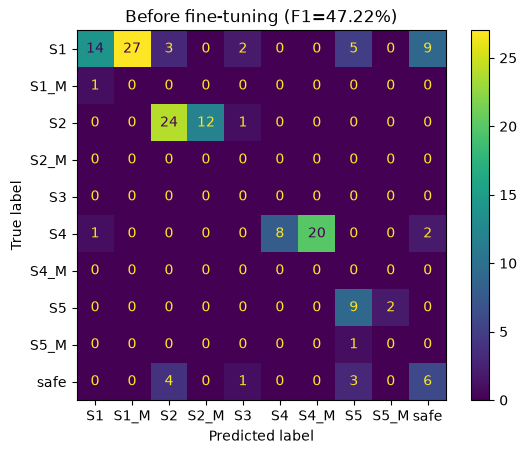

Before fine-tuning: n=100 F1=47.22% precision=79.09% recall=39.35% FPR=57.14% FNR=24.42% (TP=65 TN=6 FP=8 FN=21) errors=76/100


In [8]:
base_tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID, dtype="float16", device_map="auto")

metrics_before = validate_safety(
    base_tokenizer, base_model, eval_set, LLAMA_GUARD_3_CUSTOM_CATEGORY,
    CONFUSION_MATRIX_BEFORE, title="Before fine-tuning",
)

del base_model, base_tokenizer
free_gpu_memory()


## 8. QLoRA 微調

4-bit 量化 + LoRA（r=32），只訓練 `MAX_STEPS` 步、`TRAIN_LIMIT` 筆資料，
目的是驗證流程、展示效果，不是追求最佳準確率。訓練時間會印出來（`train_runtime`）。

In [9]:
def build_training_text(prompt, output):
    formatted_prompt = build_custom_prompt(
        agent_type=AgentType.USER,
        conversations=create_conversation([prompt]),
        categories=LLAMA_GUARD_3_CUSTOM_CATEGORY,
        category_short_name_prefix=LLAMA_GUARD_3_CATEGORY_SHORT_NAME_PREFIX,
        prompt_template=PROMPT_TEMPLATE_3,
        with_policy=True,
    )
    return formatted_prompt + output


train_pool = json.loads(TRAIN_JSON_OUT.read_text())
train_examples = train_pool[:TRAIN_LIMIT]
train_texts = [build_training_text(e["prompt"], e["output"]) for e in train_examples]
train_dataset_hf = Dataset.from_dict({"text": train_texts})
print(f"訓練資料：{len(train_dataset_hf)} 筆（訓練資料池共 {len(train_pool)} 筆）")

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
)

peft_config = LoraConfig(
    r=32,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)

training_args = SFTConfig(
    model_init_kwargs={
        "attn_implementation": "sdpa",
        "dtype": "float16",
        "use_cache": False,
        "quantization_config": quantization_config,
    },
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    warmup_steps=5,
    max_steps=MAX_STEPS,
    learning_rate=2e-4,
    optim="paged_adamw_8bit",
    logging_steps=5,
    report_to="none",
    output_dir=ADAPTER_DIR,
    max_length=1024,
    push_to_hub=False,
)

trainer = SFTTrainer(
    model=BASE_MODEL_ID,
    args=training_args,
    train_dataset=train_dataset_hf,
    peft_config=peft_config,
)
trainer_stats = trainer.train()

train_runtime = trainer_stats.metrics.get("train_runtime")
print(f"微調耗時: {train_runtime:.1f} 秒 (~{train_runtime / 60:.2f} 分鐘)")

if torch.cuda.is_available():
    vram_reserved_gb = torch.cuda.max_memory_reserved() / 1024**3
    vram_allocated_gb = torch.cuda.max_memory_allocated() / 1024**3
    gpu_total_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"VRAM 峰值：reserved={vram_reserved_gb:.2f} GB allocated={vram_allocated_gb:.2f} GB（GPU 總量 {gpu_total_gb:.2f} GB）")

trainer.save_model(ADAPTER_DIR)
print(f"adapter 存到 {ADAPTER_DIR}")

del trainer
free_gpu_memory()


訓練資料：4000 筆（訓練資料池共 21588 筆）


Truncating train dataset: 100%|██████████| 4000/4000 [00:00<00:00, 361429.93 examples/s]
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 128009}.
/workspace/playground/.venv/lib/python3.13/site-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
5,2.385464
10,1.187316
15,0.581897
20,0.475543
25,0.528199
30,0.543216
35,0.516253
40,0.492453
45,0.489539
50,0.529233


微調耗時: 230.5 秒 (~3.84 分鐘)
VRAM 峰值：reserved=10.09 GB allocated=8.60 GB（GPU 總量 79.18 GB）
adapter 存到 /workspace/playground/notebook-demo/outputs/llama_guard_lora_pii/adapter


## 9. 合併 LoRA 權重

In [10]:
import peft.tuners.lora.torchao as peft_torchao
peft_torchao.is_torchao_available = lambda: False

merge_base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID, dtype="float16", device_map="auto")
merge_tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)

fine_tuned_model = PeftModel.from_pretrained(merge_base_model, ADAPTER_DIR)
merged_model = fine_tuned_model.merge_and_unload()

Path(MERGED_DIR).mkdir(parents=True, exist_ok=True)
merged_model.save_pretrained(MERGED_DIR)
merge_tokenizer.save_pretrained(MERGED_DIR)
print(f"合併後的模型存到 {MERGED_DIR}")

del merge_base_model, merge_tokenizer, fine_tuned_model, merged_model
free_gpu_memory()


Writing model shards: 100%|██████████| 1/1 [00:38<00:00, 38.24s/it]


合併後的模型存到 /workspace/playground/notebook-demo/outputs/llama_guard_lora_pii/merged


## 10. 微調後評估（AFTER）

載入合併後的模型，對**跟 BEFORE 完全相同**的驗證集跑一次。

Prompts: 100%|██████████| 100/100 [00:07<00:00, 13.72it/s]


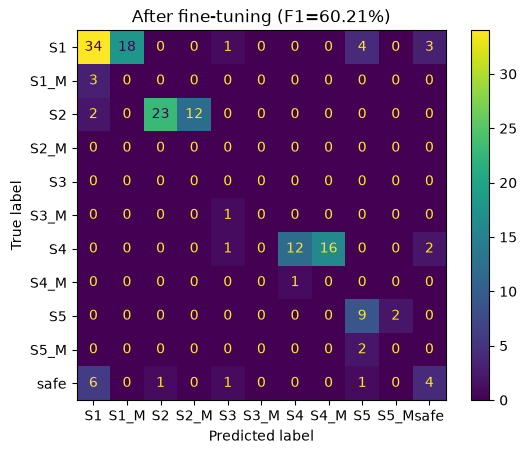

After fine-tuning: n=100 F1=60.21% precision=76.33% recall=51.57% FPR=71.43% FNR=11.63% (TP=76 TN=4 FP=10 FN=10) errors=66/100


In [11]:
ft_tokenizer = AutoTokenizer.from_pretrained(MERGED_DIR)
ft_model = AutoModelForCausalLM.from_pretrained(MERGED_DIR, dtype="float16", device_map="auto")

metrics_after = validate_safety(
    ft_tokenizer, ft_model, eval_set, LLAMA_GUARD_3_CUSTOM_CATEGORY,
    CONFUSION_MATRIX_AFTER, title="After fine-tuning",
)

del ft_model, ft_tokenizer
free_gpu_memory()


## 11. BEFORE vs AFTER 總結

微調目標：base Llama Guard 對隱私類違規只有單一籠統的 S7 (Privacy) 類別，無法區分是姓名／IP／電話／地址／信用卡，也不太會把「一段文字同時包含好幾種個資」標成多重違規。這次微調用 S1~S5 五個細分類別取代 S7，目標不是讓模型變得更會判斷『有沒有問題』（safe/unsafe 的判斷前後幾乎不變），而是讓它在判斷『有問題』之後，能更準確地列出具體是哪幾種類別、且能一次列出多個類別。

訓練資料：4000 筆（訓練資料池共 21588 筆）
驗證資料：100 筆（單一違規 + 多重違規）
微調耗時：230.5 秒 (~3.84 分鐘)
VRAM 峰值：reserved=10.09 GB allocated=8.60 GB

Before: F1=47.22%  precision=79.09%  recall=39.35%  FPR=57.14%  FNR=24.42%  (TP=65 TN=6 FP=8 FN=21)
After : F1=60.21%  precision=76.33%  recall=51.57%  FPR=71.43%  FNR=11.63%  (TP=76 TN=4 FP=10 FN=10)
F1 差異: +12.99%


/tmp/ipykernel_648896/21230765.py:39: UserWarning: Glyph 22810 (\N{CJK UNIFIED IDEOGRAPH-591A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_648896/21230765.py:39: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_648896/21230765.py:39: UserWarning: Glyph 36949 (\N{CJK UNIFIED IDEOGRAPH-9055}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_648896/21230765.py:39: UserWarning: Glyph 35215 (\N{CJK UNIFIED IDEOGRAPH-898F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_648896/21230765.py:39: UserWarning: Glyph 20597 (\N{CJK UNIFIED IDEOGRAPH-5075}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_648896/21230765.py:39: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_648896/21230765.py:39: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing f

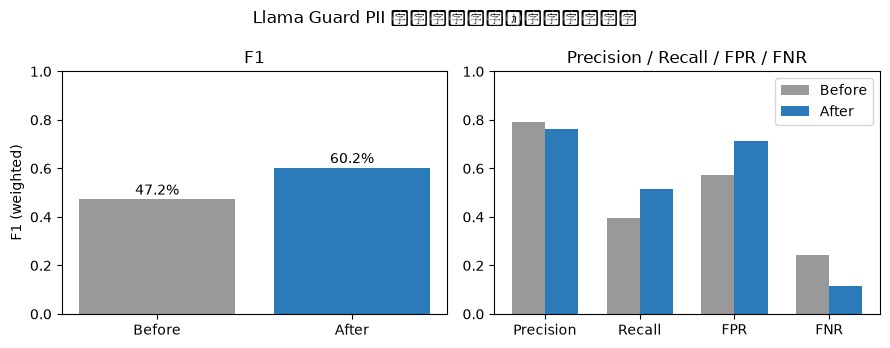

In [12]:
print(FINE_TUNE_GOAL)
print()
print(f"訓練資料：{len(train_dataset_hf)} 筆（訓練資料池共 {len(train_pool)} 筆）")
print(f"驗證資料：{len(eval_set)} 筆（單一違規 + 多重違規）")
print(f"微調耗時：{train_runtime:.1f} 秒 (~{train_runtime / 60:.2f} 分鐘)")
if torch.cuda.is_available():
    print(f"VRAM 峰值：reserved={vram_reserved_gb:.2f} GB allocated={vram_allocated_gb:.2f} GB")
print()

for label, m in [("Before", metrics_before), ("After", metrics_after)]:
    print(
        f"{label:6s}: F1={m['f1']:.2%}  precision={m['precision']:.2%}  recall={m['recall']:.2%}  "
        f"FPR={m['fpr']:.2%}  FNR={m['fnr']:.2%}  (TP={m['tp']} TN={m['tn']} FP={m['fp']} FN={m['fn']})"
    )
print(f"F1 差異: {metrics_after['f1'] - metrics_before['f1']:+.2%}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

f1_before, f1_after = metrics_before["f1"], metrics_after["f1"]
axes[0].bar(["Before", "After"], [f1_before, f1_after], color=["#999999", "#2b7bba"])
axes[0].set_ylabel("F1 (weighted)")
axes[0].set_ylim(0, 1)
for i, v in enumerate([f1_before, f1_after]):
    axes[0].text(i, v + 0.02, f"{v:.1%}", ha="center")
axes[0].set_title("F1")

metric_names = ["precision", "recall", "fpr", "fnr"]
x = range(len(metric_names))
width = 0.35
axes[1].bar([i - width / 2 for i in x], [metrics_before[k] for k in metric_names], width, label="Before", color="#999999")
axes[1].bar([i + width / 2 for i in x], [metrics_after[k] for k in metric_names], width, label="After", color="#2b7bba")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(["Precision", "Recall", "FPR", "FNR"])
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].set_title("Precision / Recall / FPR / FNR")

plt.suptitle("Llama Guard PII 多重違規偵測：微調前後對照")
plt.tight_layout()
plt.show()
